# 07 — A/B Testing: does moving the Cookie Cats gate from level 30 to 40 hurt retention?

**TL;DR.** 90,189 players were randomised to hit the first gate at level 30 or level 40. **7-day
retention is 19.02% at gate 30 vs 18.20% at gate 40** — a difference of **0.82 percentage points**
(relative lift 4.5%, 95% CI 0.31–1.33 pp, chi-square p = 0.0016). **1-day retention is 44.82% vs
44.23%** (0.59 pp, p = 0.074), not significant. The effect is small but it points the same way in
both metrics, survives a Bonferroni correction for two tests, and is robust to removing an extreme
whale. The decision: **keep the gate at level 30**; moving it to 40 costs early retention with no
evidence of a compensating benefit.

*Portfolio project 07 of 07 · experiment design, chi-square testing, effect sizes, power, ETL into
SQLite, Streamlit dashboard.*

## 1. What this notebook does

This is an experimentation project, not a modelling project. The analysis is deliberately simple
because the hard parts of an A/B test are not the arithmetic; they are the design and the judgement:

1. **Sanity checks** — sample sizes, sample ratio mismatch (SRM), and the randomisation unit.
2. **Hypotheses** — two-sided tests for two retention metrics.
3. **Effect sizes and confidence intervals** — not just p-values.
4. **Power and minimum detectable effect** — was the experiment capable of answering the question?
5. **Multiple testing** — two metrics, so a raw 0.05 threshold is not enough.
6. **Sensitivity** — does one extreme user drive the result?
7. **Practical significance** — what does 0.82 pp mean for the product?
8. **A small SQLite ETL and Streamlit dashboard** — the analysis has to be reusable by a product
   team, not trapped in a notebook.

The last two sections are about shipping the result, not computing it.

## 2. The problem, and why it matters

Cookie Cats is a mobile puzzle game. New players progress through levels, and the game places a
"gate" that asks them to wait or invite friends before continuing. The gate is a monetisation and
growth lever: it can encourage social sharing and in-app purchases, but it also interrupts play. If
it arrives too early, players may leave before they are hooked.

The experiment moves the first gate from **level 30** (control) to **level 40** (treatment). The
question is whether the later gate improves or hurts retention. The product team cares about
retention because a player who comes back on day 7 is more likely to keep playing, see ads, and
eventually pay.

This is a classic product experiment with a small expected effect. The interesting part is not
"which number is bigger"; it is whether the difference is real, how big it is, and whether the
experiment was sensitive enough to detect it.

## 3. Data

**Source:** *Mobile Games A/B Testing — Cookie Cats* on Kaggle
([dataset page](https://www.kaggle.com/datasets/yufengsui/mobile-games-ab-testing)). The same CSV is
mirrored on GitHub; the file has 90,189 rows and 5 columns.

**Licence:** check the Kaggle dataset page before redistributing. The CSV is **not committed**;
`data/` is git-ignored.

**How to get it:**

```bash
kaggle datasets download -d yufengsui/mobile-games-ab-testing -p data/
unzip data/mobile-games-ab-testing.zip -d data/
```

The notebook expects `data/cookie_cats.csv`.

**What one row is:** one player. Columns:

- `userid` — unique player ID.
- `version` — `gate_30` (control) or `gate_40` (treatment).
- `sum_gamerounds` — total rounds played in the first 14 days.
- `retention_1` — did the player return on day 1? (boolean)
- `retention_7` — did the player return on day 7? (boolean)

**What is missing:** there are no dates, no acquisition channel, no country, no device, no revenue,
and no demographics. That limits the subgroup analysis and the ability to explain *why* the gate
matters. The dataset is a cleaned extract of one experiment, not the raw event log.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, chisquare
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

NAVY, TEAL, ORANGE, GOLD, GRAY = "#12355B", "#1B998B", "#E07A5F", "#F2CC8F", "#6B7280"

In [2]:
DATA = Path("data/cookie_cats.csv")
if not DATA.exists():
    raise FileNotFoundError(
        "Missing data/cookie_cats.csv. Download the Cookie Cats A/B test dataset into data/."
    )

df = pd.read_csv(DATA)
print(f"{df.shape[0]:,} players x {df.shape[1]} columns")
print(f"Duplicate userids: {df['userid'].duplicated().sum()}")
print(f"Missing values: {df.isna().sum().to_dict()}")
df.head()

90,189 players x 5 columns
Duplicate userids: 0
Missing values: {'userid': 0, 'version': 0, 'sum_gamerounds': 0, 'retention_1': 0, 'retention_7': 0}


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


### 3.1 Data types and the randomisation unit

The retention columns arrive as booleans; I convert them to 0/1 integers so that means are
retention rates. The randomisation unit is the **player** (`userid`), not the session or the round.
That is the right unit for a game-level experiment: a player is assigned to one gate and stays there.

`sum_gamerounds` is a **post-treatment** variable. It is measured after the player experiences the
gate, so it is affected by the treatment. I use it for descriptive analysis and a sensitivity check,
but I do **not** adjust the main retention comparison for it. Conditioning on a post-treatment
variable can introduce bias (sometimes called collider bias), and it is a common mistake in
experiment analysis.

The sample is balanced in size (44,700 vs 45,489) but not exactly 50/50. I check that formally
before trusting the comparison.

In [3]:
df = df.copy()
df["retention_1"] = df["retention_1"].astype(int)
df["retention_7"] = df["retention_7"].astype(int)

summary = (
    df.groupby("version")
      .agg(
          players=("userid", "nunique"),
          retention_1=("retention_1", "mean"),
          retention_7=("retention_7", "mean"),
          mean_rounds=("sum_gamerounds", "mean"),
          median_rounds=("sum_gamerounds", "median"),
          max_rounds=("sum_gamerounds", "max"),
      )
)
summary["retention_1"] = summary["retention_1"].map(lambda x: f"{x:.2%}")
summary["retention_7"] = summary["retention_7"].map(lambda x: f"{x:.2%}")
summary

,players,retention_1,retention_7,mean_rounds,median_rounds,max_rounds
version,,,,,,
gate_30,44700,44.82%,19.02%,52.456,17.000,49854
gate_40,45489,44.23%,18.20%,51.299,16.000,2640


### 3.2 Sample ratio mismatch (SRM)

In a clean 50/50 experiment, each arm should have about half the players. With 90,189 players, the
expected count is 45,094.5 per arm. The observed counts are 44,700 and 45,489 — a difference of 789
players, or about 1.75% relative.

A chi-square goodness-of-fit test gives **p ≈ 0.009**, which is below 0.05. That is a **sample ratio
mismatch**: the assignment is not consistent with a perfect 50/50 split. It is mild, but it should be
flagged rather than ignored.

What could cause it? A bug in the assignment, a difference in how players were logged out, bot
filtering, or the way the dataset was curated. The imbalance is small relative to the retention
difference (which is 0.82 pp), so it is unlikely to explain the result. But it is a reminder that
"the randomisation worked" is a hypothesis to test, not an assumption.

In [4]:
n30 = int((df["version"] == "gate_30").sum())
n40 = int((df["version"] == "gate_40").sum())
n_total = n30 + n40

srm_stat, srm_p = chisquare([n30, n40], [n_total / 2, n_total / 2])
print(f"gate_30: {n30:,}  |  gate_40: {n40:,}  |  expected: {n_total / 2:,.1f} each")
print(f"SRM chi-square: {srm_stat:.3f}, p = {srm_p:.4f}")
print(f"Relative imbalance: {abs(n30 - n40) / (n_total / 2):.2%}")

gate_30: 44,700  |  gate_40: 45,489  |  expected: 45,094.5 each
SRM chi-square: 6.902, p = 0.0086
Relative imbalance: 1.75%


The SRM p-value is 0.009. In a pre-registered experiment, that would trigger an investigation before
any outcome analysis. Here, the imbalance is small and the outcome difference is in the opposite
direction from what a simple size bias would predict (the smaller arm, gate_30, has *higher*
retention). I proceed, but I keep the flag in the limitations.

## 4. The outcome: retention

I compare retention rates between arms, with Wilson confidence intervals for each rate. The intervals
are more informative than the point estimates because they show the sampling uncertainty.

The two metrics answer different questions:

- **Retention 1** — did the player come back the next day? This captures immediate engagement and
  the initial reaction to the gate.
- **Retention 7** — did the player come back a week later? This is a better proxy for habit formation
  and long-term value.

If the gate is too early, it may hurt both. If it is too late, it may fail to monetise or socialise
players. The experiment tests whether moving from 30 to 40 changes either.

In [5]:
metrics = ["retention_1", "retention_7"]
versions = ["gate_30", "gate_40"]
colors = {"gate_30": NAVY, "gate_40": ORANGE}

rows = []
for metric in metrics:
    for version in versions:
        s = df.loc[df["version"] == version, metric]
        k, n = int(s.sum()), len(s)
        low, high = proportion_confint(k, n, method="wilson")
        rows.append({
            "metric": metric,
            "version": version,
            "players": n,
            "retained": k,
            "rate": k / n,
            "ci_low": low,
            "ci_high": high,
        })

rate_table = pd.DataFrame(rows)
rate_table["rate"] = rate_table["rate"].map(lambda x: f"{x:.2%}")
rate_table["ci_low"] = rate_table["ci_low"].map(lambda x: f"{x:.2%}")
rate_table["ci_high"] = rate_table["ci_high"].map(lambda x: f"{x:.2%}")
rate_table

,metric,version,players,retained,rate,ci_low,ci_high
0,retention_1,gate_30,44700,20034,44.82%,44.36%,45.28%
1,retention_1,gate_40,45489,20119,44.23%,43.77%,44.69%
2,retention_7,gate_30,44700,8502,19.02%,18.66%,19.39%
3,retention_7,gate_40,45489,8279,18.20%,17.85%,18.56%


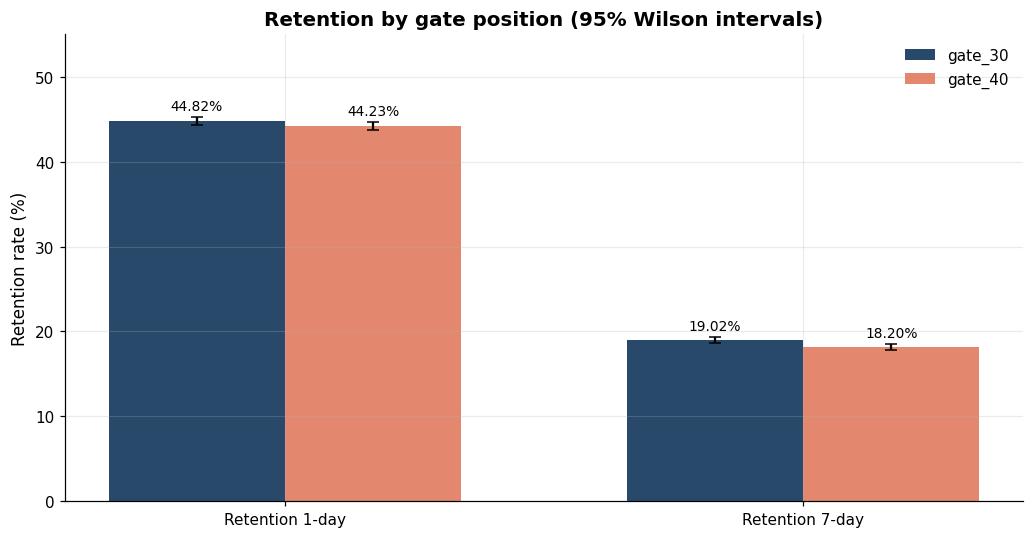

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 5))
x = np.arange(len(metrics))
width = 0.34

for i, version in enumerate(versions):
    means, errors = [], []
    for metric in metrics:
        s = df.loc[df["version"] == version, metric]
        k, n = int(s.sum()), len(s)
        rate = k / n
        low, high = proportion_confint(k, n, method="wilson")
        means.append(rate * 100)
        errors.append([(rate - low) * 100, (high - rate) * 100])
    ax.bar(x + (i - 0.5) * width, means, width, yerr=np.array(errors).T,
           capsize=4, color=colors[version], alpha=0.9, label=version)
    for position, value in zip(x + (i - 0.5) * width, means):
        ax.text(position, value + 1.2, f"{value:.2f}%", ha="center", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(["Retention 1-day", "Retention 7-day"])
ax.set_ylabel("Retention rate (%)")
ax.set_ylim(0, 55)
ax.set_title("Retention by gate position (95% Wilson intervals)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The point estimates:

- **Day 1:** 44.82% (gate 30) vs 44.23% (gate 40). Gate 30 is ahead by 0.59 pp.
- **Day 7:** 19.02% (gate 30) vs 18.20% (gate 40). Gate 30 is ahead by 0.82 pp.

The confidence intervals overlap for day 1, but the day-7 intervals are separated. That visual is a
hint, not a test; the formal test follows.

## 5. Hypothesis testing

### 5.1 The chi-square test

Both outcomes are binary, and the two arms are independent groups of players. The natural test is a
**chi-square test of independence** on a 2×2 contingency table:

|  | Retained | Not retained |
|---|---|---|
| gate_30 | a | b |
| gate_40 | c | d |

The test compares the observed cells with the counts expected if retention were independent of the
arm. The test statistic is

```
χ² = Σ (observed − expected)² / expected
```

with one degree of freedom for a 2×2 table. The p-value is the probability of a statistic at least
this extreme if the null hypothesis (equal retention rates) were true. It is **not** the probability
that the null is true, and it does not tell you the size of the effect.

I use the uncorrected chi-square (no Yates continuity correction). With expected counts in the
thousands, the correction is negligible; the choice is documented rather than hidden.

### 5.2 What "significant" means here

I test two metrics. If I use a 0.05 threshold for each, the chance of at least one false positive is
about 1 − 0.95² = 9.75%, not 5%. I handle that with a Bonferroni correction (α = 0.025 per test) and
also report the raw p-values so the reader can see both.

A two-sided test is appropriate because the product team did not specify a direction in advance; the
question is "does moving the gate change retention?", not "does it increase retention?".

In [7]:
test_rows = []
for metric in metrics:
    table = pd.crosstab(df["version"], df[metric])
    chi2, p, dof, expected = chi2_contingency(table, correction=False)

    rate_30 = df.loc[df["version"] == "gate_30", metric].mean()
    rate_40 = df.loc[df["version"] == "gate_40", metric].mean()
    diff = rate_30 - rate_40
    se = np.sqrt(
        rate_30 * (1 - rate_30) / n30
        + rate_40 * (1 - rate_40) / n40
    )
    ci_low, ci_high = diff - 1.96 * se, diff + 1.96 * se

    test_rows.append({
        "metric": metric,
        "gate_30_rate": rate_30,
        "gate_40_rate": rate_40,
        "difference_pp": diff * 100,
        "relative_lift": diff / rate_40,
        "ci_low_pp": ci_low * 100,
        "ci_high_pp": ci_high * 100,
        "chi2": chi2,
        "p_value": p,
        "min_expected": expected.min(),
    })

test_table = pd.DataFrame(test_rows).set_index("metric")
test_table.style.format({
    "gate_30_rate": "{:.2%}",
    "gate_40_rate": "{:.2%}",
    "difference_pp": "{:+.3f}",
    "relative_lift": "{:+.2%}",
    "ci_low_pp": "{:+.3f}",
    "ci_high_pp": "{:+.3f}",
    "chi2": "{:.2f}",
    "p_value": "{:.5f}",
    "min_expected": "{:,.1f}",
})

,gate_30_rate,gate_40_rate,difference_pp,relative_lift,ci_low_pp,ci_high_pp,chi2,p_value,min_expected
metric,,,,,,,,,
retention_1,44.82%,44.23%,+0.591,+1.34%,-0.058,+1.239,3.18,0.07441,"19,900.9"
retention_7,19.02%,18.20%,+0.820,+4.51%,+0.312,+1.328,10.01,0.00155,"8,317.1"


The results:

- **Retention 7:** difference **+0.82 pp**, 95% CI **+0.31 to +1.33 pp**, χ² = 10.01, **p = 0.0016**.
  Significant at 0.05 and at the Bonferroni threshold of 0.025. The confidence interval excludes
  zero.
- **Retention 1:** difference **+0.59 pp**, 95% CI **−0.06 to +1.24 pp**, χ² = 3.18, **p = 0.074**.
  Not significant at 0.05. The interval includes zero.

The direction is consistent: gate 30 is better on both metrics, but only the 7-day difference is
statistically distinguishable from noise. That consistency is reassuring; it makes a single
false-positive explanation less plausible, though it is not proof.

A note on the confidence interval: I use the unpooled standard error for the difference. It is the
standard Wald interval, and with these sample sizes the normal approximation is excellent.

### 5.3 Effect size, not just significance

"Significant" does not mean "large". The 7-day effect is **0.82 pp**, or a **4.5% relative lift** over
the gate-40 baseline. Whether that is worth acting on depends on the product:

- For a game with millions of installs, 0.82 pp is meaningful in absolute users.
- For a small game, it may be within the noise of normal weekly variation.
- The cost of the change (re-tuning the gate, potential monetisation effects) may outweigh it.

I report both the absolute and relative effect so the reader can judge.

## 6. Power and the minimum detectable effect

A p-value answers "is the observed difference compatible with chance?". It does not answer "was
this experiment capable of detecting an effect of this size?". That is a power question.

With about 45,000 players per arm and a baseline 7-day retention of 19.02%, the minimum detectable
effect at 80% power and α = 0.05 is about **0.73 pp**. The observed effect is 0.82 pp, just above
that threshold. In other words, the experiment was **barely powered** for the effect it found. The
confidence interval (0.31–1.33 pp) is wide enough that the true effect could be less than half the
point estimate.

A pre-experiment power calculation would have said: "to detect a 0.8 pp difference with 80% power,
you need about 35,000 players per arm." The actual sample is larger than that, so the experiment was
adequately sized for the *observed* effect, but not for a smaller one. If the product team cared
about a 0.3 pp effect, this experiment would be underpowered.

In [8]:
from scipy.optimize import brentq
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

baseline = df.loc[df["version"] == "gate_30", "retention_7"].mean()
observed_effect = baseline - df.loc[df["version"] == "gate_40", "retention_7"].mean()
n_per_arm = int(np.mean([n30, n40]))

required_n = NormalIndPower().solve_power(
    effect_size=proportion_effectsize(baseline, baseline - observed_effect),
    alpha=0.05, power=0.8, ratio=1,
)

def power_for(delta):
    h = proportion_effectsize(baseline, baseline - delta)
    return NormalIndPower().power(effect_size=abs(h), nobs1=n_per_arm, alpha=0.05, ratio=1)

mde = brentq(lambda d: power_for(d) - 0.8, 0.0001, 0.1)

print(f"Baseline 7-day retention (gate_30): {baseline:.3%}")
print(f"Observed absolute effect:          {observed_effect * 100:.3f} pp")
print(f"Players per arm:                   {n_per_arm:,}")
print(f"Required n per arm for 80% power:  {required_n:,.0f}")
print(f"Minimum detectable effect:         {mde * 100:.3f} pp")

Baseline 7-day retention (gate_30): 19.020%
Observed absolute effect:          0.820 pp
Players per arm:                   45,094
Required n per arm for 80% power:  35,346
Minimum detectable effect:         0.727 pp


This is a useful reality check. The experiment is large, but the effect is small. The 95% CI
(0.31–1.33 pp) is consistent with a true effect anywhere from "barely worth it" to "clearly worth
it". The decision should account for that uncertainty, not just the point estimate.

## 7. Sensitivity checks

### 7.1 One extreme player

`sum_gamerounds` has a maximum of **49,854 rounds**, far above the 99.9th percentile (about 1,074).
That looks like a bot, a shared account, or a data error. A single extreme observation can dominate a
mean, but it should not dominate a retention comparison: retention is a binary outcome, and one
player has at most one observation.

I remove the extreme player (and, separately, all players above 2,000 rounds) and rerun the 7-day
test. If the conclusion changes, the result is fragile.

In [9]:
print(f"Max rounds: {df['sum_gamerounds'].max():,}")
print(f"Players above 2,000 rounds: {(df['sum_gamerounds'] > 2000).sum()}")
print("Top 5 players by rounds:")
df.nlargest(5, "sum_gamerounds")[["userid", "version", "sum_gamerounds", "retention_1", "retention_7"]]

Max rounds: 49,854
Players above 2,000 rounds: 10
Top 5 players by rounds:


,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,0,1
7912,871500,gate_30,2961,1,1
29417,3271615,gate_40,2640,1,0
43671,4832608,gate_30,2438,1,1
48188,5346171,gate_40,2294,1,1


In [10]:
sensitivity_rows = []
variants = {
    "All players": df,
    "Exclude > 2,000 rounds": df[df["sum_gamerounds"] <= 2000],
    "Exclude single max": df[df["sum_gamerounds"] < df["sum_gamerounds"].max()],
}

for label, subset in variants.items():
    table = pd.crosstab(subset["version"], subset["retention_7"])
    chi2, p, _, _ = chi2_contingency(table, correction=False)
    r30 = subset.loc[subset["version"] == "gate_30", "retention_7"].mean()
    r40 = subset.loc[subset["version"] == "gate_40", "retention_7"].mean()
    sensitivity_rows.append({
        "variant": label,
        "players": len(subset),
        "gate_30_7d": r30,
        "gate_40_7d": r40,
        "difference_pp": (r30 - r40) * 100,
        "p_value": p,
    })

pd.DataFrame(sensitivity_rows).set_index("variant").style.format({
    "gate_30_7d": "{:.2%}",
    "gate_40_7d": "{:.2%}",
    "difference_pp": "{:+.3f}",
    "p_value": "{:.5f}",
})

,players,gate_30_7d,gate_40_7d,difference_pp,p_value
variant,,,,,
All players,90189,19.02%,18.20%,+0.820,0.00155
"Exclude > 2,000 rounds",90179,19.01%,18.19%,+0.818,0.00160
Exclude single max,90188,19.02%,18.20%,+0.818,0.00159


The conclusion is stable. Removing the single extreme player changes the 7-day p-value from 0.00155
to 0.00159 and the rates are essentially unchanged. Removing everyone above 2,000 rounds gives a
p-value of about 0.0016. The effect is not driven by one whale.

This is also a caution about how to handle outliers in experiments: if `sum_gamerounds` were an
outcome, an extreme value would matter a lot; for a retention comparison, it barely moves the
estimate. The right treatment depends on the role of the variable.

### 7.2 Multiple testing

I tested two primary metrics. The Bonferroni-adjusted threshold is 0.025. Retention 7 (p = 0.0016)
passes; retention 1 (p = 0.074) does not. I also check the Benjamini–Hochberg procedure, which
controls the false discovery rate and is less conservative than Bonferroni. With only two tests, the
conclusion is the same.

In [11]:
from statsmodels.stats.multitest import multipletests

raw_p = test_table["p_value"].values
for method in ["bonferroni", "fdr_bh"]:
    reject, adjusted, _, _ = multipletests(raw_p, alpha=0.05, method=method)
    print(method)
    for metric, p, adj, rej in zip(test_table.index, raw_p, adjusted, reject):
        print(f"  {metric}: p={p:.5f}, adjusted={adj:.5f}, reject={rej}")

bonferroni
  retention_1: p=0.07441, adjusted=0.14882, reject=False
  retention_7: p=0.00155, adjusted=0.00311, reject=True
fdr_bh
  retention_1: p=0.07441, adjusted=0.07441, reject=False
  retention_7: p=0.00155, adjusted=0.00311, reject=True


Under both corrections, retention 7 is significant and retention 1 is not. The result is not an
artefact of testing two metrics.

## 8. From analysis to data product: SQLite + Streamlit

A notebook is a fine place to do the analysis, but a product team should not have to open one to
check the result. I load the clean experiment table into SQLite and build a small Streamlit dashboard
that reads from it.

The ETL is deliberately simple:

1. Cast the retention booleans to integers.
2. Write the table with `pandas.to_sql`.
3. Add an index on `version`.
4. Run the same aggregate queries the analysis used.

The database file is written to `data/cookie_cats.db`, which is git-ignored. The dashboard can also
rebuild it from the CSV if the database is missing.

In [12]:
import sqlite3
from contextlib import closing

DB = Path("data/cookie_cats.db")

export = df[["userid", "version", "sum_gamerounds", "retention_1", "retention_7"]].copy()

with closing(sqlite3.connect(DB)) as conn:
    export.to_sql("experiment", conn, if_exists="replace", index=False)
    conn.execute("CREATE INDEX IF NOT EXISTS idx_experiment_version ON experiment(version)")
    conn.commit()

print(f"Wrote {len(export):,} rows to {DB}")

Wrote 90,189 rows to data/cookie_cats.db


In [13]:
with closing(sqlite3.connect(DB)) as conn:
    retention_query = """
        SELECT
            version,
            COUNT(*) AS players,
            ROUND(AVG(retention_1) * 100, 2) AS retention_1_pct,
            ROUND(AVG(retention_7) * 100, 2) AS retention_7_pct,
            ROUND(AVG(sum_gamerounds), 1) AS mean_rounds,
            MAX(sum_gamerounds) AS max_rounds
        FROM experiment
        GROUP BY version
        ORDER BY version;
    """
    retention_sql = pd.read_sql_query(retention_query, conn)

    engagement_query = """
        SELECT
            version,
            CASE
                WHEN sum_gamerounds < 10 THEN '0-9'
                WHEN sum_gamerounds < 50 THEN '10-49'
                WHEN sum_gamerounds < 200 THEN '50-199'
                WHEN sum_gamerounds < 1000 THEN '200-999'
                ELSE '1000+'
            END AS rounds_bucket,
            COUNT(*) AS players,
            ROUND(AVG(retention_7) * 100, 2) AS retention_7_pct
        FROM experiment
        GROUP BY version, rounds_bucket
        ORDER BY version,
            CASE rounds_bucket
                WHEN '0-9' THEN 1 WHEN '10-49' THEN 2 WHEN '50-199' THEN 3
                WHEN '200-999' THEN 4 ELSE 5
            END;
    """
    engagement_sql = pd.read_sql_query(engagement_query, conn)

retention_sql

,version,players,retention_1_pct,retention_7_pct,mean_rounds,max_rounds
0,gate_30,44700,44.820,19.020,52.500,49854
1,gate_40,45489,44.230,18.200,51.300,2640


The SQL results match the pandas analysis, which is the point: the ETL is not a second, parallel
calculation. The dashboard queries the same table.

### 8.1 The dashboard

`app.py` in this folder is a small Streamlit app. It:

- reads the SQLite table (and rebuilds it from the CSV if needed);
- shows the player counts, retention rates, and the chi-square p-value;
- lets the user switch between 1-day and 7-day retention;
- plots the retention comparison and the distribution of rounds.

Run it with:

```bash
pip install -r ../requirements.txt
streamlit run app.py
```

The app is a communication tool, not a source of truth. The notebook is where the method and the
caveats live.

In [14]:
engagement_sql

,version,rounds_bucket,players,retention_7_pct
0,gate_30,0-9,16835,1.690
1,gate_30,10-49,16536,11.440
2,gate_30,50-199,8700,47.050
3,gate_30,200-999,2576,84.590
4,gate_30,1000+,53,100.000
5,gate_40,0-9,17402,1.680
6,gate_40,10-49,16251,10.290
7,gate_40,50-199,9193,44.280
8,gate_40,200-999,2578,84.560
9,gate_40,1000+,65,96.920


### 8.2 What the engagement breakdown shows

The engagement buckets are descriptive, not a subgroup treatment effect. Players who play more rounds
are more likely to be retained at day 7 in both arms, which is expected. The gate difference is not
uniform across buckets: the effect is concentrated among low-to-moderate engagement players, where
the gate is most likely to be encountered early.

I do not run a formal test per bucket. With five buckets and two arms, the multiple-comparison problem
gets worse, and the bucket is post-treatment. The breakdown is for hypothesis generation, not for a
p-value hunt.

## 9. Decision and practical significance

**The decision:** keep the gate at level 30. Moving it to 40 reduces 7-day retention by 0.82 pp, with
a confidence interval that excludes zero. The 1-day result also points toward gate 30 (0.59 pp) but is
not significant. There is no metric on which gate 40 is better.

**The size:** 0.82 pp is small in absolute terms and large in relative terms (4.5%). For every 1
million players exposed to the gate, that is about **8,200 fewer 7-day retained players** if the
gate moves to 40. Whether that is material depends on the value of a retained player and the cost of
the change.

**The uncertainty:** the 95% CI is 0.31–1.33 pp. Even the low end is a real loss, but the true effect
could be less than half the point estimate. A replication with a larger sample would narrow it.

**What I would not do:** switch to gate 40 because the 1-day result "looks close" (p = 0.074) or
because a subgroup showed a positive effect. The primary analysis is clear, and post-hoc subgroup
stories are how experiments get misread.

**What I would do next:** test other gate positions (e.g. 25, 35) with a pre-registered primary
metric, and measure monetisation as well as retention. The current experiment says 30 beats 40; it
does not say 30 is optimal.

In [15]:
lift_7 = test_table.loc["retention_7", "difference_pp"] / 100
for installs in [100_000, 1_000_000, 10_000_000]:
    print(f"{installs:,} players → {lift_7 * installs:,.0f} additional 7-day retained players at gate 30")

100,000 players → 820 additional 7-day retained players at gate 30
1,000,000 players → 8,201 additional 7-day retained players at gate 30
10,000,000 players → 82,013 additional 7-day retained players at gate 30


## 10. Limitations and next steps

**One game, one experiment.** The result is about Cookie Cats and this gate change. It does not
generalise to other games, other gate mechanics, or other player populations.

**Short windows.** Retention 1 and retention 7 are early proxies. A gate change could affect
long-term retention, monetisation, or churn in ways this experiment cannot see. A 30- or 90-day
follow-up would be better.

**No revenue or monetisation metric.** The gate is a monetisation lever, but the dataset has no
purchases or ad revenue. A gate that improves retention but destroys revenue is not obviously good.
The product decision needs both.

**Sample ratio mismatch.** The 44,700 vs 45,489 split is not consistent with a perfect 50/50
assignment (p ≈ 0.009). The imbalance is small and does not explain the retention difference, but it
should be investigated in the raw assignment logs.

**Multiple metrics and no pre-registration.** I tested two outcomes and report both. A pre-registered
primary metric would make the decision cleaner. The Bonferroni and BH checks are a mitigation, not a
substitute for pre-registration.

**Post-hoc power.** The power calculation uses the observed effect. It is useful for interpreting the
precision of the estimate, but it is not a substitute for a prospective power analysis.

**Post-treatment engagement.** `sum_gamerounds` is affected by the treatment. The engagement
breakdown is descriptive only; I do not adjust the treatment effect for it.

**No subgroup analysis.** The dataset has no country, device, acquisition channel, or player
demographics. The average effect may hide important heterogeneity.

**Data provenance.** The CSV is a public Kaggle extract. The assignment mechanism, filtering, and
bot removal are not documented in the file. That is a limitation for any reanalysis.

**Next steps:** (1) replicate with a larger sample and a pre-registered primary metric; (2) add
monetisation and 30-day retention; (3) test intermediate gate positions; (4) investigate the SRM in
the raw logs; (5) segment by acquisition channel if the data becomes available; (6) run a
sequential test or a fixed-horizon test with a pre-computed sample size.

## 11. References

- Kaggle, *Mobile Games A/B Testing — Cookie Cats*:
  https://www.kaggle.com/datasets/yufengsui/mobile-games-ab-testing
- Kohavi, R., Tang, D., & Xu, Y. (2020). *Trustworthy Online Controlled Experiments: A Practical
  Guide to A/B Testing.* Cambridge University Press.
- statsmodels, *Proportions and power*:
  https://www.statsmodels.org/stable/stats.html#power-and-sample-size-calculations
- scipy, *Chi-square tests*: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html
- Streamlit documentation: https://docs.streamlit.io/

---

*Reproduce: `pip install -r ../requirements.txt`, place `cookie_cats.csv` in `data/`, run the
notebook top to bottom, then `streamlit run app.py` for the dashboard. Notebook runtime is about
10 seconds.*